In [1]:
import preprocessamento as pp
import treinamento as tr

import pandas as pd
pd.set_option('display.max_columns', None)
import yfinance as yf


In [2]:
from datetime import datetime, timedelta

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import precision_recall_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
papel = 'RENT3.SA'
papeis_adicionais = ['MOVI3.SA', 'ECOR3.SA']

In [5]:
# Parâmetros
DIAS_VALIDACAO = 90  # número de dias para simular produção

In [6]:
base = datetime.today().date() #- timedelta(days=1)
df_base = pp.montar_dataset(papel, dias_total_historico=600, data_base=base)
df_base = pp.buscar_dados_papeis_adicionais(df_base, papeis_adicionais)
df_base.tail(10)

[RENT3.SA] Cache existente cobre de 2020-01-02 a 2025-07-03.
[RENT3.SA] Cache NÃO cobre período solicitado. Download total necessário.
[RENT3.SA] Iniciando download de dados (lógica de atualização/complemento)...
[RENT3.SA] Período de download yfinance: 2020-01-01 a 2025-07-14
Index(['data', 'adj_close', 'close', 'Dividends', 'high', 'low', 'open',
       'Stock Splits', 'volume'],
      dtype='object', name='Price')
[RENT3.SA] Realizando verificação de divergência entre cache antigo e dados frescos...
[RENT3.SA] Pós-Download Total: Nenhuma divergência significativa nas amostras (tolerância 1.00%).
[RENT3.SA] Cache principal ATUALIZADO com dados frescos: /palpiteiro/dados\RENT3.csv
[RENT3.SA] Retornando 613 linhas para o período solicitado.
⬇️ Baixando dados macro de 22/01/2022 a 11/07/2025...
Baixando série 432 (selic)...
Baixando série 433 (ipca)...
Baixando série 1 (dolar)...
💾 Dados salvos em cache: /palpiteiro/dados\macro_20220122_20250711.csv
[^BVSP] Cache existente cobre de 2020

,open,high,low,close,adj_close,volume,pct_change,vol,rsi,macd,macd_signal,macd_hist,tr,atr,atr_pct,tr_pct,mm5,mm20,selic,ipca,dolar,open_ibov,high_ibov,low_ibov,close_ibov,adj_close_ibov,volume_ibov,adc_open_MOVI3,adc_high_MOVI3,adc_low_MOVI3,adc_close_MOVI3,adc_adj_close_MOVI3,adc_volume_MOVI3,adc_pct_change_MOVI3,adc_vol_MOVI3,adc_rsi_MOVI3,adc_macd_MOVI3,adc_macd_signal_MOVI3,adc_macd_hist_MOVI3,adc_tr_MOVI3,adc_atr_MOVI3,adc_atr_pct_MOVI3,adc_tr_pct_MOVI3,adc_mm5_MOVI3,adc_mm20_MOVI3,adc_open_ECOR3,adc_high_ECOR3,adc_low_ECOR3,adc_close_ECOR3,adc_adj_close_ECOR3,adc_volume_ECOR3,adc_pct_change_ECOR3,adc_vol_ECOR3,adc_rsi_ECOR3,adc_macd_ECOR3,adc_macd_signal_ECOR3,adc_macd_hist_ECOR3,adc_tr_ECOR3,adc_atr_ECOR3,adc_atr_pct_ECOR3,adc_tr_pct_ECOR3,adc_mm5_ECOR3,adc_mm20_ECOR3
data,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2025-06-26,42.299999,42.299999,40.009998,40.009998,39.510548,33754000,-0.072769,0.029271,36.686683,0.181390,0.645885,-0.464495,3.140003,1.522030,0.038041,0.078480,42.467999,43.5735,15.0,0.26,5.5145,135767.000,137353.000,135756.00000,137114.000000,137114.000000,7773826,8.68,8.75,7.35,7.50,7.50,20638800,-0.138921,0.066659,49.560117,0.416226,0.389315,0.026912,1.40,0.523450,0.069793,0.186667,8.270,7.5515,7.55,7.57,7.34,7.48,7.48,2505900,-0.002667,0.032268,57.440515,0.232490,0.236458,-0.003968,0.23,0.309949,0.041437,0.030749,7.500,7.2735
2025-06-27,39.840000,41.430000,39.820000,40.549999,40.043808,14095200,0.013497,0.029511,39.762802,-0.031427,0.510422,-0.541849,1.610001,1.528313,0.037690,0.039704,41.925999,43.4290,15.0,0.26,5.4759,137113.000,137209.000,136469.00000,136866.000000,136866.000000,3731569,7.50,7.74,7.11,7.11,7.11,12720200,-0.052000,0.063951,45.494426,0.315955,0.374643,-0.058688,0.63,0.531061,0.074692,0.088608,8.038,7.5555,7.41,7.60,7.21,7.37,7.37,3176000,-0.014706,0.032795,54.513133,0.211024,0.231371,-0.020347,0.39,0.315667,0.042831,0.052917,7.476,7.3005
2025-06-30,40.220001,41.220001,39.669998,40.520000,40.520000,8503600,-0.000740,0.029614,39.647558,-0.200199,0.368298,-0.568497,1.550003,1.529863,0.037756,0.038253,41.548000,43.3070,15.0,0.26,5.4571,136865.000,139103.000,136430.00000,138855.000000,138855.000000,4715665,7.13,7.24,6.88,7.01,7.01,9974500,-0.014065,0.063525,44.486678,0.225817,0.344878,-0.119061,0.36,0.518842,0.074015,0.051355,7.828,7.5585,7.37,7.52,7.26,7.49,7.49,2882400,0.016282,0.032850,57.082732,0.201374,0.225371,-0.023998,0.26,0.311691,0.041614,0.034713,7.494,7.3375
2025-07-01,40.540001,41.099998,39.830002,40.630001,40.630001,6266600,0.002715,0.028036,40.330479,-0.321371,0.230364,-0.551735,1.269997,1.511301,0.037197,0.031258,40.972000,43.1730,15.0,0.26,5.4511,138855.000,139695.000,138855.00000,139549.000000,139549.000000,2903180,7.03,7.18,6.88,6.95,6.95,6986800,-0.008559,0.060165,43.858921,0.147836,0.305469,-0.157634,0.30,0.503210,0.072404,0.043165,7.456,7.5655,7.49,7.67,7.32,7.66,7.66,3712100,0.022697,0.023072,60.488073,0.205079,0.221313,-0.016234,0.35,0.314427,0.041048,0.045692,7.500,7.3725
2025-07-02,40.689999,40.759998,37.980000,38.290001,38.290001,15943300,-0.057593,0.031833,32.027958,-0.599311,0.064429,-0.663740,2.779999,1.601922,0.041837,0.072604,40.000000,42.9315,15.0,0.26,5.4512,139586.000,140049.000,138384.00000,139051.000000,139051.000000,3619807,6.96,6.99,6.57,6.66,6.66,6836400,-0.041727,0.059421,40.857923,0.061921,0.256760,-0.194839,0.42,0.497267,0.074665,0.063063,7.046,7.5585,7.68,7.68,7.18,7.30,7.30,9481600,-0.046997,0.027050,51.219705,0.176928,0.212436,-0.035508,0.50,0.327683,0.044888,0.068493,7.460,7.3785
2025-07-03,38.400002,39.480000,37.980000,39.250000,39.250000,8454500,0.025072,0.033707,37.694793,-0.733659,-0.095189,-0.638471,1.500000,1.594642,0.040628,0.038217,39.848000,42.7090,15.0,0.26,5.4208,139051.000,141304.000,139051.00000,140928.000000,140928.000000,3879378,6.69,7.02,6.67,7.00,7.00,5530700,0.051051,0.061370,45.561017,0.021026,0.209613,-0.188587,0.36,0.487462,0.069637,0.051429,6.946,7.5700,7.31,7.47,7.24,7.30,7.30,2497300,0.000000,0.0251

## Verificação da volatilidade recente

In [7]:
df_base[['atr', 'atr_pct', 'tr', 'tr_pct']].tail(10)

,atr,atr_pct,tr,tr_pct
data,,,,
2025-06-26,1.522030,0.038041,3.140003,0.078480
2025-06-27,1.528313,0.037690,1.610001,0.039704
2025-06-30,1.529863,0.037756,1.550003,0.038253
2025-07-01,1.511301,0.037197,1.269997,0.031258
2025-07-02,1.601922,0.041837,2.779999,0.072604
2025-07-03,1.594642,0.040628,1.500000,0.038217
2025-07-04,1.532168,0.039106,0.720001,0.018377
2025-07-07,1.518441,0.039246,1.340000,0.034634
2025-07-08,1.487124,0.038849,1.080002,0.028213


In [8]:
ultimo_atr_pct = df_base['atr_pct'].iloc[-1]
multiplo_atr = 1.5
valorizacao_sugerida = ultimo_atr_pct * multiplo_atr
print(f'Último ATR %: {ultimo_atr_pct:.2%}')
print(f'Valorização sugerida: {valorizacao_sugerida:.2%}') 

Último ATR %: 4.13%
Valorização sugerida: 6.20%


## Re-preparação dos dados com valorização sugerida (calibrar dias_futuro de acordo com balanceamento da base)

In [11]:
valorizacao = 0.07
stop_loss = 0.045
DIAS_FUTURO = 5  # dias futuros para buscar a valorização

In [12]:
df = pp.calcular_target_com_stop(df_base, valorizacao_alvo_pct=valorizacao, dias_horizonte_alvo=DIAS_FUTURO, stop_loss_pct=stop_loss)
df['Target'].value_counts(normalize=True)

Target
0.0    0.848684
1.0    0.151316
Name: proportion, dtype: float64

In [13]:
# estudo de qual tamanho de janela é melhor para este papel
tamanhos_janela = [6, 10, 15, 20, 30, 60]
lista_f1_treino = []
lista_f1_validacao = []
lista_pr_auc_treino = []
lista_pr_auc_validacao = []

for tamanho_janela in tamanhos_janela:
    X, y = pp.preparar_X_y_agregado(df, tamanho_janela, dropna=True, tipo_drop_na='linhas')   

    X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)
    X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
    X_validacao = X_validacao[X_train.columns]

    modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced')
    modelo.fit(X_train.values, y_train.values)

    roc_treino, roc_validacao, diferenca, pr_auc_treino, pr_auc_validacao, f1_score_treino, f1_score_validacao = tr.comparar_auc_conjuntos(modelo, X_train, y_train, X_validacao, y_validacao)

    lista_f1_treino.append(f1_score_treino)
    lista_f1_validacao.append(f1_score_validacao)

    lista_pr_auc_treino.append(pr_auc_treino)
    lista_pr_auc_validacao.append(pr_auc_validacao)

df_resultados = pd.DataFrame({
    'Tamanho Janela': tamanhos_janela,
    'F1 Treino': lista_f1_treino,
    'F1 Validação': lista_f1_validacao,
    'PR AUC Treino': lista_pr_auc_treino,
    'PR AUC Validação': lista_pr_auc_validacao
})

INFO: Papéis adicionais detectados para features: ['MOVI3', 'ECOR3']
INFO: 29 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.626
AUC na validação: 0.567
Diferença AUC (Treino - Validação): 0.059
PR AUC no treino: 0.368
PR AUC na validação: 0.433
Diferença PR AUC (Treino - Validação): -0.065
F1 Score no treino: 0.266
F1 Score na validação: 0.450
INFO: Papéis adicionais detectados para features: ['MOVI3', 'ECOR3']
INFO: 25 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.655
AUC na validação: 0.536
Diferença AUC (Treino - Validação): 0.119
PROVÁVEL OVERFITTING
PR AUC no treino: 0.380
PR AUC na validação: 0.377
Diferença PR AUC (Treino - Validação): 0.003
F1 Score no treino: 0.265
F1 Score na validação: 0.452
INFO: Papéis adicionais detectados para features: ['MOVI3', 'ECOR3']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


... (3 outputs left out)

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.709
AUC na validação: 0.453
Diferença AUC (Treino - Validação): 0.256
PROVÁVEL OVERFITTING
PR AUC no treino: 0.415
PR AUC na validação: 0.348
Diferença PR AUC (Treino - Validação): 0.067
F1 Score no treino: 0.308
F1 Score na validação: 0.466
INFO: Papéis adicionais detectados para features: ['MOVI3', 'ECOR3']


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


AUC no treino: 0.714
AUC na validação: 0.552
Diferença AUC (Treino - Validação): 0.161
PROVÁVEL OVERFITTING
PR AUC no treino: 0.395
PR AUC na validação: 0.392
Diferença PR AUC (Treino - Validação): 0.002
F1 Score no treino: 0.287
F1 Score na validação: 0.432


In [14]:
df_resultados.sort_values(by='PR AUC Validação', ascending=False)

,Tamanho Janela,F1 Treino,F1 Validação,PR AUC Treino,PR AUC Validação
2,15,0.283906,0.433511,0.367740,0.512719
0,6,0.266196,0.450229,0.368462,0.433122
3,20,0.214018,0.400748,0.337316,0.417520
5,60,0.286737,0.431698,0.394643,0.392236
1,10,0.264672,0.451863,0.380436,0.377260
4,30,0.308052,0.465824,0.414909,0.347750


In [15]:
# Preparar X e y para treino
DIAS_JANELA_X = 15  # janela de dados recentes que formam cada X
X, y = pp.preparar_X_y_agregado(df, DIAS_JANELA_X, dropna=True, tipo_drop_na='linhas')   

X_train, y_train, X_validacao, y_validacao = tr.dividir_treino_validacao(X, y, DIAS_VALIDACAO, dias_futuro=DIAS_FUTURO)

INFO: Papéis adicionais detectados para features: ['MOVI3', 'ECOR3']
INFO: 20 linha(s) removidas de X e y devido a NaNs (dropna='linhas').


In [16]:
X_train, removidas = tr.eliminar_features_correlacionadas(X_train, limite_correlacao=0.95, target=y_train)
X_validacao = X_validacao[X_train.columns]
print("Features removidas por alta correlação:", removidas)
print(f"Colunas restantes após filtragem: {X_train.shape[1]}")

Features removidas por alta correlação: ['retorno_acumulado', 'macd_mean', 'ibov_amplitude', 'tr_std', 'macd_hist_std', 'macd_ultimo_norm_atr_principal', 'adc_atr_pct_ultimo_MOVI3', 'close_amplitude', 'close_ult_vs_mm_janela', 'macd_signal_ultimo_norm_atr_principal', 'dias_alta_pct', 'macd_std_norm_atr_principal', 'close_trend', 'close_mean', 'macd_signal_std_norm_atr_principal', 'macd_ultimo', 'close_min', 'rsi_mean', 'macd_hist_ultimo_norm_atr_principal', 'close_amplitude_norm_atr_principal', 'adc_atr_pct_mean_geral_ultimo']
Colunas restantes após filtragem: 60


In [17]:
X_train.tail()

,close_std,close_max,retorno_desde_mudanca_close,close_dist_min,close_vs_mm20,mm5_vs_mm20,retorno_mean,retorno_std,dias_queda_pct,retorno_medio_pos,retorno_medio_neg,volume_mean,volume_std,volume_trend,volume_ult_vs_mean,atr_ultimo,atr_pct_ultimo,rsi_std,rsi_ultimo,macd_std,macd_signal_mean,macd_signal_std,macd_signal_ultimo,macd_hist_mean,macd_hist_ultimo,macd_hist_std_norm_atr_principal,tr_mean,tr_ultimo,tr_std_norm_atr_principal,tr_ultimo_norm_atr_principal,tr_pct_mean,tr_pct_std,tr_pct_ultimo,close_std_norm_atr_principal,adc_close_trend_MOVI3,adc_ret_acum_MOVI3,adc_rsi_ultimo_MOVI3,adc_macd_hist_ultimo_MOVI3,adc_correl_com_principal_MOVI3,adc_close_trend_ECOR3,adc_ret_acum_ECOR3,adc_rsi_ultimo_ECOR3,adc_atr_pct_ultimo_ECOR3,adc_macd_hist_ultimo_ECOR3,adc_correl_com_principal_ECOR3,adc_close_mean_geral_ultimo,close_vs_adc_close_mean_geral,adc_ret_acum_mean_geral_janela,selic_ultimo,ipca_ultimo,dolar_ultimo,dolar_trend,dolar_std,retorno_desde_mudanca_dolar,ibov_trend,ibov_std,retorno_desde_mudanca_ibov,correl_papel_ibov,beta_papel_ibov,alpha_papel_vs_ibov_mean
2025-02-12,0.696243,31.889999,0.000000,0.740000,-0.005494,-0.003096,0.000736,0.029538,0.466667,0.021958,-0.023518,9.918653e+06,3.407199e+06,255300.000000,0.820560,1.305019,0.042536,4.235883,46.167885,0.322962,-0.990067,0.367920,-0.519186,0.306137,0.129237,0.073454,1.293333,1.010000,0.370918,0.773935,0.041832,0.015923,0.032920,0.533512,-2.396428e-02,-0.013263,48.030566,0.018986,0.545104,0.003000,0.026915,50.607460,0.049234,-0.001353,0.827089,4.340,6.069124,0.006826,13.25,0.16,5.7711,-0.012879,0.062114,-0.001332,172.014286,1390.227826,0.000000,0.814278,2.028160,-0.000407
2025-02-13,0.727703,31.889999,-0.030639,0.000000,-0.035183,-0.016237,-0.000215,0.030347,0.466667,0.021958,-0.025555,1.022734e+07,3.453426e+06,280985.000000,0.258157,1.315375,0.044229,3.828166,41.652532,0.277781,-0.917501,0.346913,-0.506113,0.290262,0.052289,0.088345,1.324667,1.450001,0.363008,1.102348,0.042906,0.015802,0.048756,0.553229,-2.728571e-02,-0.051075,42.868479,0.013791,0.585289,-0.003821,0.030928,51.767590,0.047209,-0.004218,0.789609,4.265,5.973036,-0.010074,13.25,0.16,5.7788,-0.011469,0.057030,0.000000,98.860714,1212.842969,0.000000,0.772260,1.992101,-0.003823
2025-02-14,0.723301,31.889999,0.000000,1.870001,0.023540,-0.007286,0.003333,0.034421,0.466667,0.028611,-0.025555,1.080033e+07,3.511472e+06,298624.285714,0.401856,1.375705,0.043521,3.656269,51.760289,0.231117,-0.847764,0.321146,-0.474795,0.278950,0.125273,0.089941,1.407334,2.160000,0.369806,1.570104,0.045439,0.016665,0.068333,0.525767,-1.667856e-02,0.067533,57.784136,0.047998,0.705945,-0.002929,0.037109,59.673055,0.046255,0.013466,0.830983,4.710,5.711253,0.052321,13.25,0.16,5.7283,-0.012101,0.059404,0.000000,100.450000,1222.886075,0.026984,0.802643,2.054523,-0.003763
2025-02-17,0.796319,32.470001,0.027207,2.730001,0.048180,0.004148,0.002091,0.033088,0.466667,0.026281,-0.025555,1.106873e+07,3.556033e+06,327958.571429,0.219210,1.401726,0.043170,4.234733,55.572090,0.210122,-0.780714,0.296121,-0.418880,0.268198,0.223662,0.086207,1.404000,1.740002,0.361138,1.241328,0.045248,0.016546,0.053588,0.568099,1.362392e-08,0.118110,60.645721,0.077557,0.716860,0.008786,0.113360,63.609902,0.046402,0.035414,0.816428,4.880,5.653689,0.115735,13.25,0.16,5.7105,-0.011599,0.056913,-0.003107,166.675000,1484.279809,0.032191,0.794988,2.103016,-0.002881
2025-02-18,0.827940,32.470001,0.000000,2.260000,0.030612,0.008068,0.001841,0.033205,0.466667,0.026281,-0.026091,1.138983e+07,3.278623e+06,180341.071429,-0.044586,1.393032,0.043532,4.468129,53.102497,0.203643,-0.716415,0.274208,-0.357022,0.257198,0.247430,0.081903,1.434001,1.280003,0.346403,0.918861,0.046151,0.015800,0.040000,0.594344,1.257144e-02,0.085271,58.925125,0.089075,0.717973,0.010750,0.076152,59.341307,0.046791,0.038382,0.830705,4.785,5.687566,0.080712,13.25,0.16,5.6979,-0.011616,0.056990,-0.005307,187.135714,1564.386665,0.000000,0.798618,2.027153,-0.001342


# LogisticRegression

In [21]:
modelo_rl = LogisticRegression(solver='liblinear', random_state=42, class_weight='balanced') #
modelo_rl.fit(X_train, y_train)
tr.comparar_auc_conjuntos(modelo_rl, X_train, y_train, X_validacao, y_validacao)

AUC no treino: 0.698
AUC na validação: 0.551
Diferença AUC (Treino - Validação): 0.147
PROVÁVEL OVERFITTING
PR AUC no treino: 0.368
PR AUC na validação: 0.513
Diferença PR AUC (Treino - Validação): -0.145
F1 Score no treino: 0.284
F1 Score na validação: 0.434


(np.float64(0.6981192057581861),
 np.float64(0.5506670658068177),
 np.float64(0.1474521399513684),
 np.float64(0.3677401960713113),
 np.float64(0.5127186987141336),
 np.float64(0.2839059998288846),
 np.float64(0.43351056648692016))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: b6b73342914045748d0a7ea701f1ef52 para RENT3.SA_15dias_x_0.07val_5dias_alvo
AUC no treino: 0.714
AUC na validação: 0.688

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.698
  Precisão média (em 400 janelas com previsão positiva): 0.192
  Recall médio: 0.534

Calibrando thresholds para precisão mínima de 0.70...
Nenhum threshold atendeu à precisão mínima de 0.70. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.310
Recall médio: 0.949
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 86
Modelo RENT3.SA_15dias_x_0.07val_5dias_alvo salvo na run b6b73342914045748d0a7ea701f1ef52


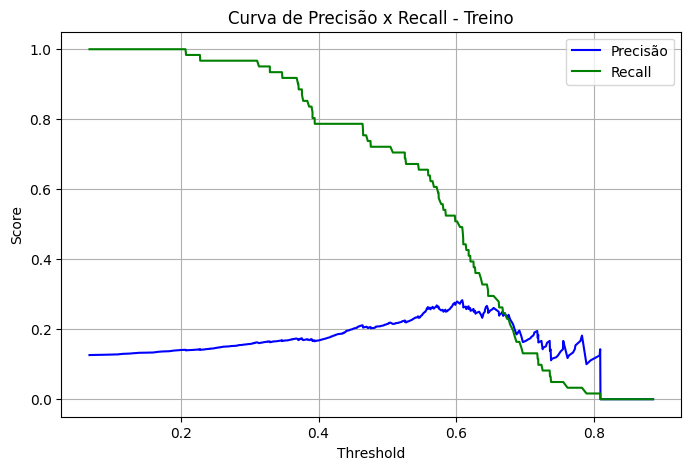

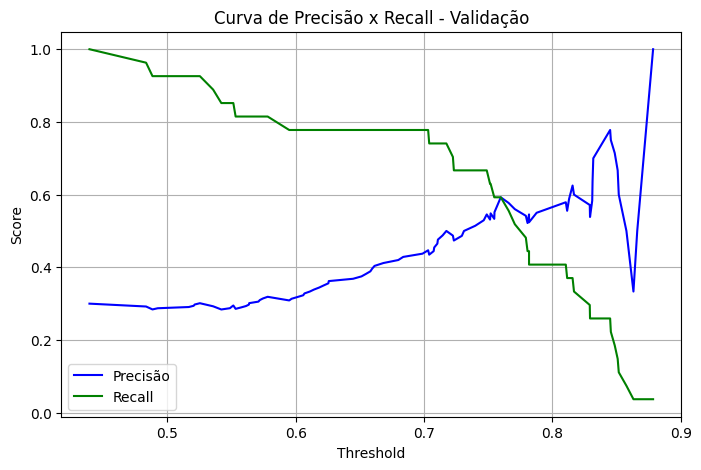

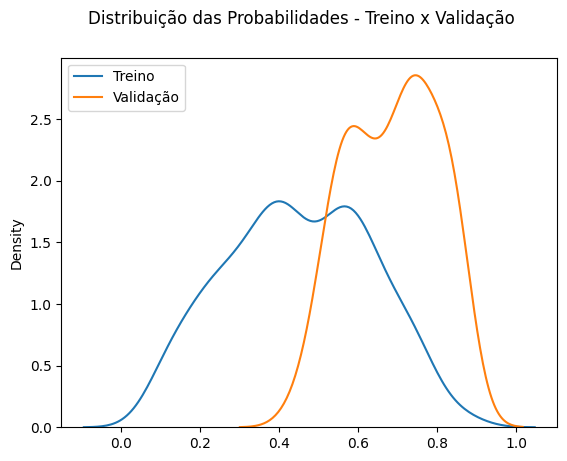

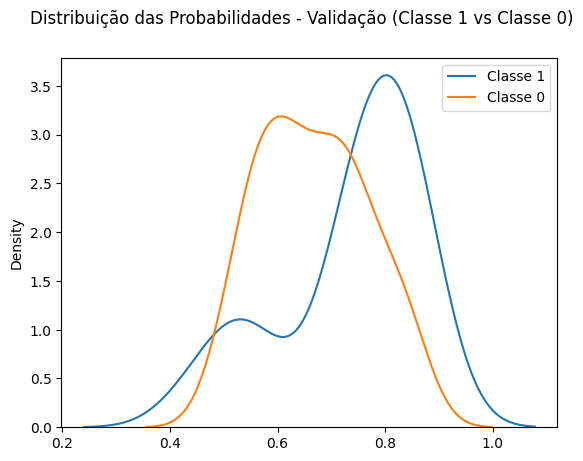

In [ ]:
recall_minimo = None
precisao_minima = 0.
resultado = tr.avaliar_e_logar_modelo(modelo_rl, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# Redução de features

In [23]:
# Importâncias
importancias = pd.Series(modelo_rl.coef_[0], index=X_train.columns)
df_importancias = pd.DataFrame({
    'Feature': importancias.index,
    'importancia': importancias.values,
    'importancia_abs': importancias.abs().values
})
df_importancias.sort_values(by='importancia_abs', ascending=False, inplace=True)
df_importancias.head(15)


,Feature,importancia,importancia_abs
18,rsi_ultimo,-0.057167,0.057167
1,close_max,-0.046865,0.046865
41,adc_rsi_ultimo_ECOR3,0.045091,0.045091
36,adc_rsi_ultimo_MOVI3,0.044973,0.044973
17,rsi_std,0.021503,0.021503
3,close_dist_min,-0.014050,0.014050
20,macd_signal_mean,-0.013662,0.013662
45,adc_close_mean_geral_ultimo,-0.012073,0.012073
48,selic_ultimo,0.008809,0.008809
22,macd_signal_ultimo,-0.007006,0.007006


In [24]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k)['Feature'].tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2})
            modelo.fit(X_train[colunas_selecionadas], y_train )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, df_importancias)

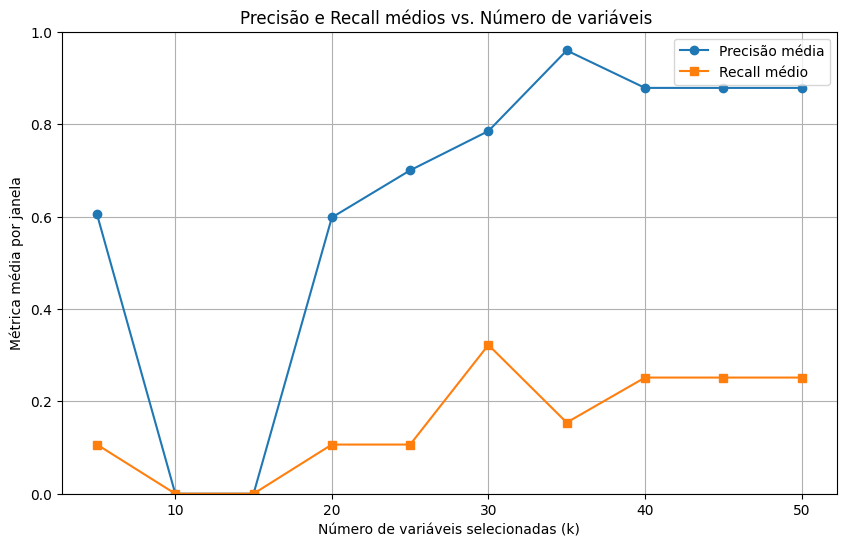

In [26]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis ")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [23]:
n_features = 30
lista_colunas_selecionadas = df_importancias.head(n_features)['Feature'].tolist()
lista_colunas_selecionadas

['ibov_trend',
 'ibov_std',
 'adc_rsi_ultimo_BEEF3',
 'close_min',
 'beta_papel_ibov',
 'adc_close_mean_geral_ultimo',
 'rsi_std',
 'close_amplitude_norm_atr_principal',
 'macd_signal_ultimo_norm_atr_principal',
 'rsi_ultimo',
 'adc_correl_com_principal_BEEF3',
 'macd_ultimo_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'correl_papel_ibov',
 'adc_rsi_ultimo_BRFS3',
 'macd_signal_mean',
 'macd_hist_ultimo_norm_atr_principal',
 'dolar_ultimo',
 'volume_trend',
 'volume_mean',
 'close_dist_min',
 'tr_ultimo',
 'atr_ultimo',
 'close_ult_vs_mm_janela',
 'tr_mean',
 'volume_std',
 'dias_queda_pct',
 'adc_close_trend_BRFS3',
 'selic_ultimo',
 'close_vs_adc_close_mean_geral']

In [24]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [25]:
modelo_rl_reduzido = LogisticRegression(solver='liblinear', random_state=42, class_weight={0:1, 1:2}, C=0.01)
modelo_rl_reduzido.fit(X_train_reduzido, y_train)
tr.comparar_auc_conjuntos(modelo_rl_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

AUC no treino: 0.616
AUC na validação: 0.685
Diferença AUC (Treino - Validação): -0.069
PR AUC no treino: 0.403
PR AUC na validação: 0.581
Diferença PR AUC (Treino - Validação): -0.178
F1 Score no treino: 0.167
F1 Score na validação: 0.460


(np.float64(0.61573168169936),
 np.float64(0.6845639864715255),
 np.float64(-0.06883230477216551),
 np.float64(0.4030261757267178),
 np.float64(0.5809797586775162),
 np.float64(0.16726031952016596),
 np.float64(0.4595838591389478))

Avaliar e logar modelo
MLflow Run ID: 930336eb262e4ab9886aaa852619bf97 para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.627
AUC na validação: 0.687

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.616
  Precisão média (em 276 janelas com previsão positiva): 0.541
  Recall médio: 0.126

Calibrando thresholds para precisão mínima de 0.65...

Threshold Ideal Selecionado: 0.54
  Precisão Média Esperada: 67.19%
  Recall Médio Esperado: 10.87%
  Janelas Usadas para Precisão: 216.0

Threshold ideal baseado em mínimo recall ou precisão: 0.54

--- Conjunto de Validação --- Janelas
Precisão média (em 61 janelas com previsão positiva): 0.592
Recall médio: 0.316
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 12
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run 930336eb262e4ab9886aaa852619bf97


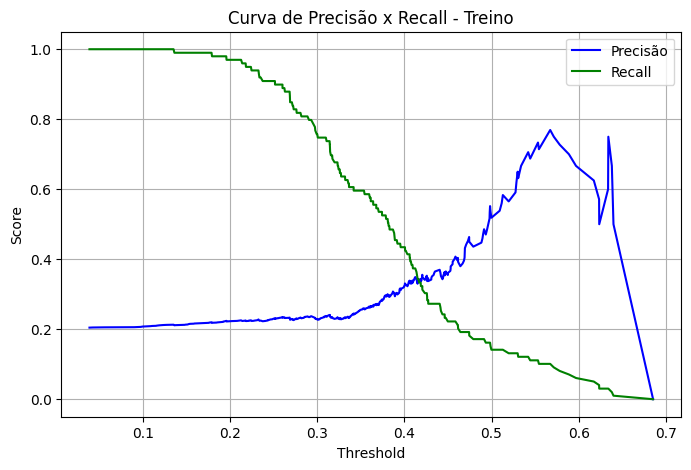

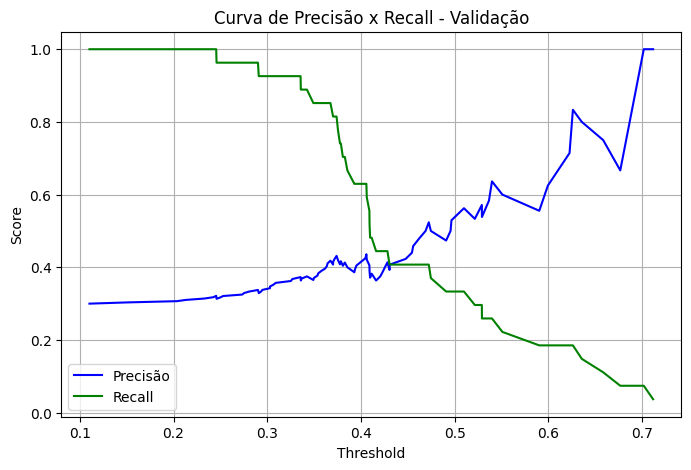

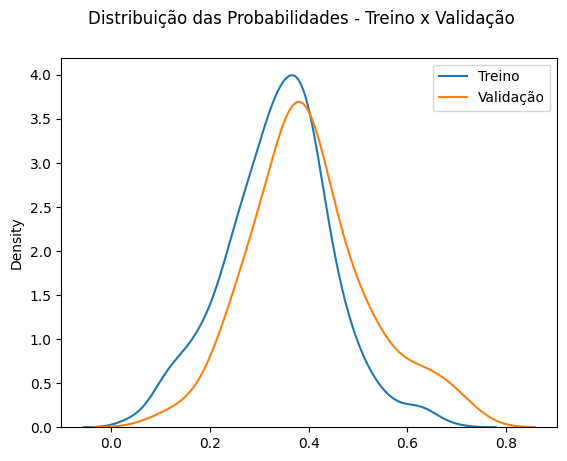

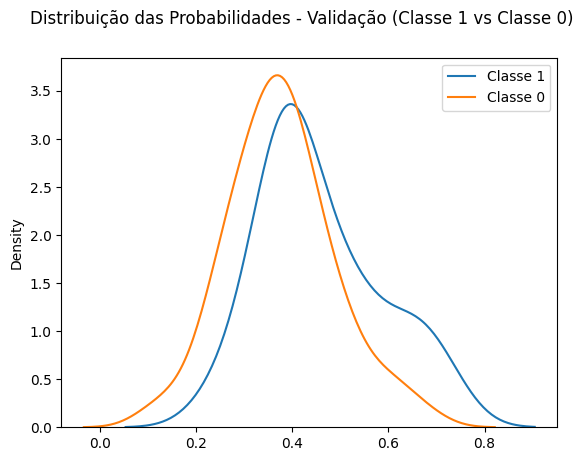

In [26]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_rl_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss, dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

# LGBM GOOGLE

## Versão com early stopping

In [27]:
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit # Para o CV interno da calibração, se optar por essa via
from sklearn.metrics import roc_auc_score
import lightgbm as lgbm # Para o callback de early stopping
from sklearn.frozen import FrozenEstimator

def criar_e_treinar_modelo_final_com_es_e_calib(
        X_super_treino_completo: pd.DataFrame, # Seus 510 dias
        y_super_treino_completo: pd.Series,
        fracao_eval_es: float = 0.2, # % do X_super_treino a ser usado para eval_set do Early Stopping
        lgbm_params: dict = None,
        early_stopping_rounds_lgbm: int = 50,
        eval_metric_lgbm: str = 'auc',
        calibrar_modelo: bool = True,
        metodo_calibracao: str = 'isotonic',
        # Opção A para calibração: usar o mesmo eval_set_es para cv='prefit'
        # Opção B para calibração: usar TimeSeriesSplit no X_treino_base_lgbm para cv do CalibratedCV
        estrategia_calibracao_cv = 'prefit' # ou um objeto TimeSeriesSplit(n_splits=3)
        , class_weight: str = 'balanced' 
    ):
    """
    Treina o modelo final (LGBM) usando uma parte do X_super_treino_completo para treino
    e outra parte para early stopping. Opcionalmente calibra o modelo.

    Retorna o modelo final treinado (e possivelmente calibrado).
    """
    if not (0 < fracao_eval_es < 1):
        raise ValueError("fracao_eval_es deve estar entre 0 e 1 (exclusivo).")

    n_total_super_treino = len(X_super_treino_completo)
    n_eval_es = int(n_total_super_treino * fracao_eval_es)
    n_treino_base_lgbm = n_total_super_treino - n_eval_es

    if n_treino_base_lgbm < 50 or n_eval_es < 20: # Mínimos arbitrários, ajuste conforme necessário
        raise ValueError(f"Dados insuficientes no X_super_treino para o split de early stopping. "
                         f"Treino Base: {n_treino_base_lgbm}, Eval ES: {n_eval_es}")

    X_treino_base_lgbm = X_super_treino_completo.iloc[:n_treino_base_lgbm]
    y_treino_base_lgbm = y_super_treino_completo.iloc[:n_treino_base_lgbm]
    X_eval_set_es = X_super_treino_completo.iloc[n_treino_base_lgbm:]
    y_eval_set_es = y_super_treino_completo.iloc[n_treino_base_lgbm:]

    print(f"Dividindo Super Treino ({n_total_super_treino} amostras):")
    print(f"  - Treino Base LGBM: {len(X_treino_base_lgbm)} amostras")
    print(f"  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): {len(X_eval_set_es)} amostras")

    # --- 1. Treinar LGBM com Early Stopping ---
    if lgbm_params is None:
        lgbm_params = {
            'n_estimators': 1000, 'learning_rate': 0.01, 'num_leaves': 8,
            'max_depth': 3, 'min_child_samples': 20, 'subsample': 0.8,
            'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1,
            'class_weight': class_weight,
            'importance_type': 'gain', 
            'verbose': -1 # Desativa logs do LGBM

        }

    modelo_lgbm = LGBMClassifier(**lgbm_params)
    print(f"\nIniciando treinamento LGBM com early stopping (monitorando '{eval_metric_lgbm}')...")

    # Certificar que X_treino_base_lgbm.values e X_eval_set_es.values são usados se as funções esperam arrays
    # Se X são DataFrames, LGBM geralmente lida bem, mas para consistência com sklearn:
    X_treino_lgbm_arr = X_treino_base_lgbm.values if isinstance(X_treino_base_lgbm, pd.DataFrame) else X_treino_base_lgbm
    y_treino_lgbm_arr = y_treino_base_lgbm.values if isinstance(y_treino_base_lgbm, pd.Series) else y_treino_base_lgbm
    X_eval_es_arr = X_eval_set_es.values if isinstance(X_eval_set_es, pd.DataFrame) else X_eval_set_es
    y_eval_es_arr = y_eval_set_es.values if isinstance(y_eval_set_es, pd.Series) else y_eval_set_es

    modelo_lgbm.fit(
        X_treino_lgbm_arr, y_treino_lgbm_arr,
        eval_set=[(X_eval_es_arr, y_eval_es_arr)],
        eval_metric=eval_metric_lgbm,
        callbacks=[lgbm.early_stopping(stopping_rounds=early_stopping_rounds_lgbm, verbose=10)]
    )
    print(f"Treinamento LGBM concluído. Melhor iteração: {modelo_lgbm.best_iteration_}")
    # Após o ES, o modelo_lgbm já está treinado com o número ótimo de árvores.

    if not calibrar_modelo:
        return modelo_lgbm # Retorna o LGBM treinado sem calibração

    # --- 2. Calibrar o Modelo Treinado ---
    print(f"\nCalibrando o LGBM treinado (método: {metodo_calibracao})...")
    
    

    if estrategia_calibracao_cv == "prefit":
        # Usa o X_eval_set_es para treinar o calibrador.
        # Este conjunto já foi "visto" para determinar n_estimators, então não é 100% puro
        # para calibração, mas é uma prática comum.
        print(f"  Usando conjunto de early stopping ({len(X_eval_set_es)} amostras) para treinar o calibrador (cv='prefit').")

        modelo_frozen = FrozenEstimator(modelo_lgbm) # Congela o modelo LGBM treinado com ES
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_frozen, # O modelo LGBM JÁ TREINADO com ES e congelado
            method=metodo_calibracao            
            )
        modelo_final_calibrado.fit(X_eval_es_arr, y_eval_es_arr)
    elif isinstance(estrategia_calibracao_cv, TimeSeriesSplit):
        modelo_final_calibrado = CalibratedClassifierCV(
            modelo_lgbm, # O modelo LGBM JÁ TREINADO com ES
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv # Pode ser "prefit" ou um objeto TimeSeriesSplit
            )
        # Treina o CalibratedClassifierCV no X_treino_base_lgbm.
        # O CalibratedCV irá internamente usar o LGBM (já com n_estimators ótimo)
        # e fazer cross-validation no X_treino_base_lgbm para ajustar o calibrador.
        # O estimador base (LGBM) NÃO é retreinado do zero pelo CalibratedCV se já tiver fit e cv='prefit'
        # MAS, se cv é um objeto splitter, ele *pode* retreinar o base_estimator em cada fold.
        # Para evitar retreinar o LGBM que já teve ES, a abordagem com 'prefit' é mais direta.
        # Se você quiser usar um splitter para o CV da calibração, é mais seguro
        # passar um LGBM *não treinado* para CalibratedCV, e o CalibratedCV fará o fit
        # do LGBM e do calibrador em seus folds internos. Mas aí você perde o ES global.
        
        # A maneira mais limpa se não usar 'prefit' para o CalibratedCV é
        # fazer com que ele treine um LGBM novo (sem ES global) em seus folds.
        # Ou, você pode fazer o ES em cada fold do CalibratedCV (mais complexo).

        # Simplificação: Se não for 'prefit', vamos assumir que você quer que o CalibratedCV
        # treine o LGBM base (com os params definidos) e o calibrador nos folds do X_treino_base_lgbm.
        # Isso ignora o `modelo_lgbm` treinado com ES anteriormente, a menos que
        # o `base_estimator` do CalibratedCV seja clonado e o `n_estimators` ótimo seja setado.
        # Vamos manter a lógica de 'prefit' como principal ou usar CV no conjunto de treino base.
        print(f"  Usando TimeSeriesSplit no Treino Base LGBM ({len(X_treino_base_lgbm)} amostras) para treinar o calibrador.")
        
        # Reinstanciar o LGBM com os parâmetros e n_estimators ótimos
        # para ser usado pelo CalibratedClassifierCV com seu próprio CV.
        # Isso garante que o n_estimators do ES seja usado em cada fold do CalibratedCV.
        params_lgbm_com_best_iter = modelo_lgbm.get_params()
        if hasattr(modelo_lgbm, 'best_iteration_') and modelo_lgbm.best_iteration_ is not None:
             params_lgbm_com_best_iter['n_estimators'] = modelo_lgbm.best_iteration_
        
        lgbm_para_calib_cv = LGBMClassifier(**params_lgbm_com_best_iter)

        modelo_final_calibrado_cv = CalibratedClassifierCV(
            lgbm_para_calib_cv,
            method=metodo_calibracao,
            cv=estrategia_calibracao_cv
        )
        modelo_final_calibrado_cv.fit(X_treino_lgbm_arr, y_treino_lgbm_arr) # Treina no treino base
        print("Calibração com CV interno concluída.")
        return modelo_final_calibrado_cv # Retorna o modelo calibrado com CV
    else:
        raise ValueError(f"estrategia_calibracao_cv desconhecida: {estrategia_calibracao_cv}. Use 'prefit' ou um objeto TimeSeriesSplit.")

    print("Calibração concluída.")
    return modelo_final_calibrado, modelo_lgbm

In [32]:
# --- Seu fluxo principal (para cada papel) ---
# Supondo que X_super_train_papel, y_super_train_papel (510 dias)
# e X_validacao_final_papel, y_validacao_final_papel (90 dias) estão definidos.

# 1. Treinar o modelo
#    Você escolhe a estratégia de calibração:
#    Opção A: Calibrar com 'prefit' usando o mesmo eval_set do ES (mais simples, pequeno reuso)
modelo_treinado, modelo_original = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train, y_train,
    fracao_eval_es=0.25, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'
    , class_weight='balanced' # Ajuste conforme necessário
)
#modelo_treinado.fit(X_train.values, y_train.values)  # Fit final após calibração

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_treinado, X_train, y_train, X_validacao, y_validacao)

Dividindo Super Treino (484 amostras):
  - Treino Base LGBM: 363 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 121 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[54]	valid_0's auc: 0.512579	valid_0's binary_logloss: 0.658605
Treinamento LGBM concluído. Melhor iteração: 54

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (121 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.780
AUC na validação: 0.522
Diferença AUC (Treino - Validação): 0.259
PROVÁVEL OVERFITTING
PR AUC no treino: 0.389
PR AUC na validação: 0.316
Diferença PR AUC (Treino - Validação): 0.073
F1 Score no treino: 0.000
F1 Score na validação: 0.000


(np.float64(0.780256106765063),
 np.float64(0.5216750933633679),
 np.float64(0.25858101340169504),
 np.float64(0.38885334286425555),
 np.float64(0.31633082508865346),
 np.float64(0.0),
 np.float64(0.0))

Avaliar e logar modelo
MLflow Tracking URI definido para: file:///C:/palpiteiro/mlruns
Experimento 'Modelo_B3' já existe (ID: 378581376299543397).
  Artifact Location existente: file:///C:/palpiteiro/mlruns/378581376299543397
MLflow Run ID: e89bfdad4ef5474cbd7ef326406fa678 para RENT3.SA_15dias_x_0.07val_5dias_alvo
AUC no treino: 0.801
AUC na validação: 0.582

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.685
  Precisão média (em 0 janelas com previsão positiva): 0.000
  Recall médio: 0.000

Calibrando thresholds para precisão mínima de 0.65...
Nenhum threshold atendeu à precisão mínima de 0.65. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 0 janelas com previsão positiva): 0.000
Recall médio: 0.000
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 0
Modelo RENT3.SA_15dias_x_0.07val_5dias_alvo salvo na run e89bfdad4ef5474cbd7ef326406fa678


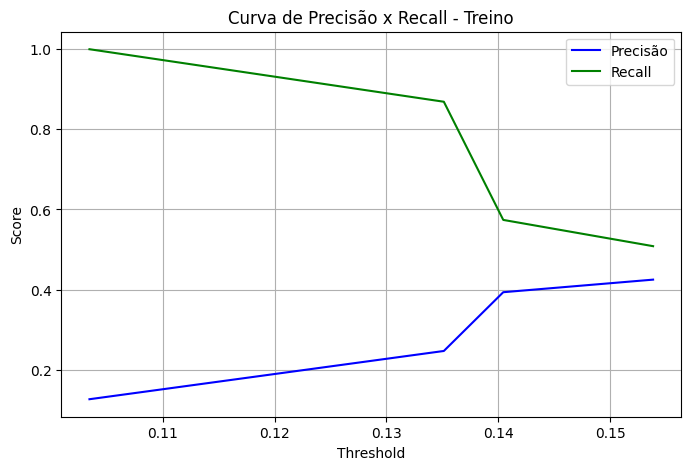

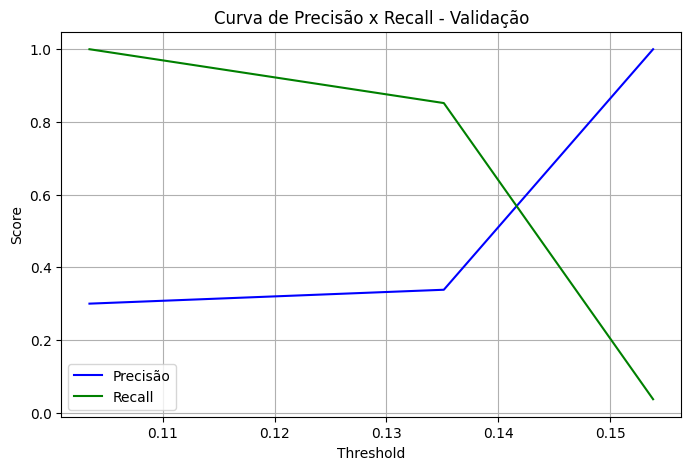

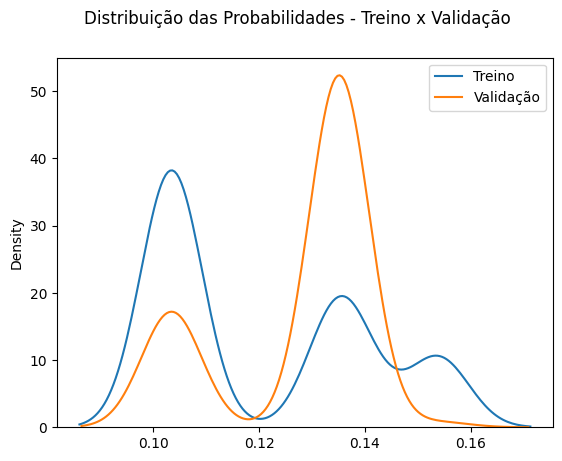

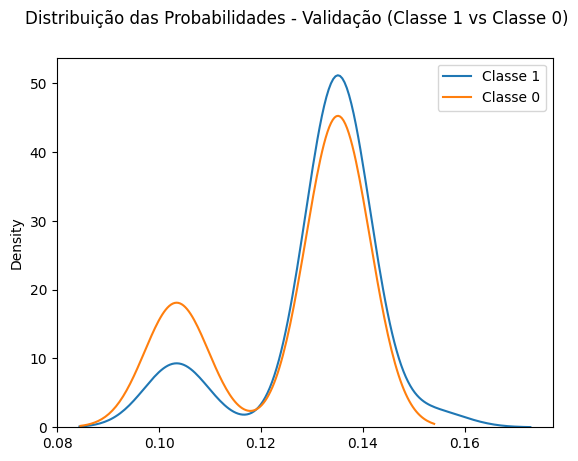

In [30]:
recall_minimo = None
precisao_minima = 0.65
resultado = tr.avaliar_e_logar_modelo(modelo_treinado, papel, X_train, y_train, X_validacao, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, stop_loss=stop_loss,dias_futuro_valorizacao=DIAS_FUTURO,dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

(<Axes: >,
 count    90.000000
 mean      0.210782
 std       0.176741
 min       0.000000
 25%       0.000000
 50%       0.194444
 75%       0.357143
 max       0.500000
 dtype: float64)

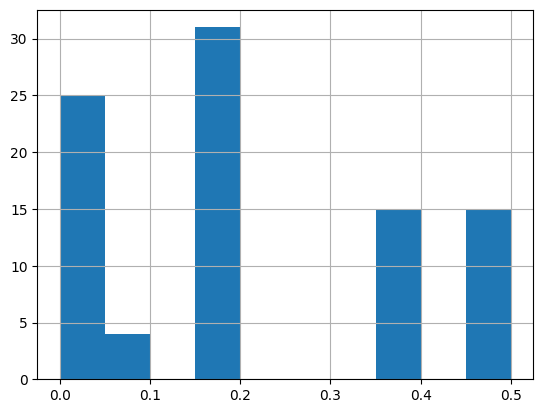

In [ ]:
pd.Series(probas).hist(), pd.Series(probas).describe()

# Redução de features

In [41]:
# Importâncias
importancias = pd.Series(modelo_original.feature_importances_, index=X_train.columns)
importancias = importancias.sort_values(ascending=False)
importancias.head(15)


atr_ultimo                       69.221703
adc_atr_pct_ultimo_CCRO3         50.912300
adc_atr_pct_mean_geral_ultimo    44.627602
close_max                        39.753399
dolar_trend                      16.542900
volume_ult_vs_mean                3.408560
close_std                         0.000000
retorno_desde_mudanca_close       0.000000
retorno_std                       0.000000
close_dist_min                    0.000000
close_vs_mm20                     0.000000
retorno_medio_neg                 0.000000
retorno_medio_pos                 0.000000
volume_std                        0.000000
volume_mean                       0.000000
dtype: float64

In [42]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

def avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_valid, y_valid, k_values, importancias, janela_treino=180, janela_teste=30):
    resultados_precisao = {}
    resultados_recall = {}

    for k in k_values:        
        colunas_selecionadas = importancias.head(k).index.tolist()        
        precisões = []
        recalls = []

        for i in range(0, len(X_valid) - janela_teste):
            X_val_teste = X_valid.iloc[i:i + janela_teste][colunas_selecionadas]
            y_val_teste = y_valid.iloc[i:i + janela_teste]

            #modelo = RandomForestClassifier(n_estimators=100, random_state=42)
            
            modelo, _ = criar_e_treinar_modelo_final_com_es_e_calib(
                X_train[colunas_selecionadas], y_train,
                fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
                estrategia_calibracao_cv='prefit'
            )            

            y_pred = modelo.predict(X_val_teste)

            if (y_pred == 1).sum() > 0:
                # Se não houver predições positivas, não calcular precisão e recall
                
                prec = precision_score(y_val_teste, y_pred, zero_division=0)
                rec = recall_score(y_val_teste, y_pred, zero_division=0)

                precisões.append(prec)
                recalls.append(rec)

        resultados_precisao[k] = np.mean(precisões)
        resultados_recall[k] = np.mean(recalls)

    return resultados_precisao, resultados_recall

# Altere se quiser outro intervalo de k
k_values = list(range(5, min(51, X_train.shape[1] + 1), 5))
#k_values = [18, 20, 22, 25]
resultados_precisao, resultados_recall = avaliar_precisao_recall_por_k_janelas(X_train, y_train, X_validacao, y_validacao, k_values, importancias)

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM con

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1]	valid_0's auc: 0.570881	valid_0's binary_logloss: 0.697095
Treinamento LGBM concluído. Melhor iteração: 1

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early S

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

... (182 outputs left out)

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[2]	valid_0's auc: 0.483397	valid_0's binary_logloss: 0.690197
Treinamento LGBM concluído. Melhor iteração: 2

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[2]	valid_0's auc: 0.483397	valid_0's binary_logloss: 0.690197
Treinamento LGBM con

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[2]	valid_0's auc: 0.483397	valid_0's binary_logloss: 0.690197
Treinamento LGBM concluído. Melhor iteração: 2

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (96 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.
Dividindo Super Treino (483 amostras):
  - Treino Base LGBM: 387 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 96 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[2]	valid_0's auc: 0.483397	valid_0's binary_logloss: 0.690197
Treinamento LGBM con

c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

In [43]:
resultados_precisao

{5: np.float64(nan),
 10: np.float64(nan),
 15: np.float64(nan),
 20: np.float64(nan),
 25: np.float64(nan),
 30: np.float64(nan),
 35: np.float64(nan),
 40: np.float64(nan),
 45: np.float64(nan),
 50: np.float64(nan)}

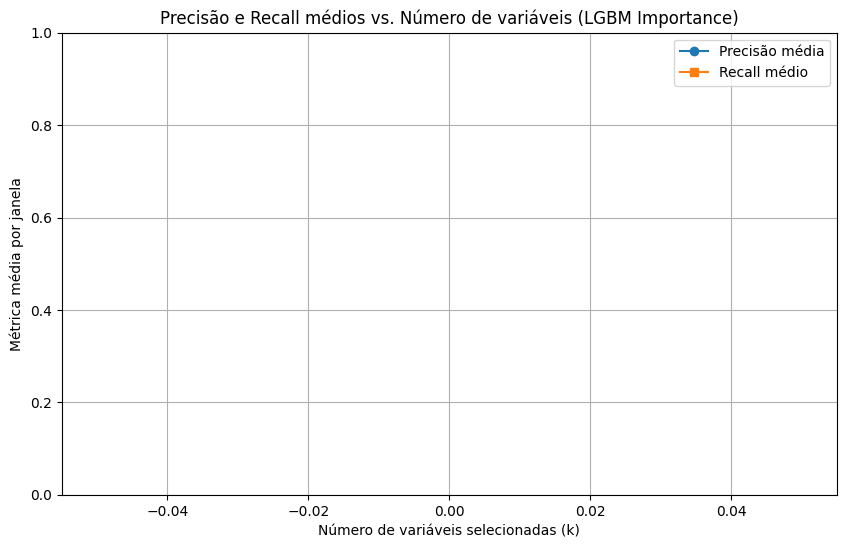

In [44]:
plt.figure(figsize=(10, 6))
plt.plot(resultados_precisao.keys(), resultados_precisao.values(), marker='o', label='Precisão média')
plt.plot(resultados_recall.keys(), resultados_recall.values(), marker='s', label='Recall médio')
plt.title("Precisão e Recall médios vs. Número de variáveis (LGBM Importance)")
plt.xlabel("Número de variáveis selecionadas (k)")
plt.ylabel("Métrica média por janela")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

# Features reduzidas

In [ ]:
n_features = 55
lista_colunas_selecionadas = importancias.head(n_features).index.tolist()
lista_colunas_selecionadas

['close_vs_adc_close_mean_geral',
 'adc_correl_com_principal_BEEF3',
 'dolar_trend',
 'close_amplitude_norm_atr_principal',
 'adc_correl_com_principal_BRFS3',
 'macd_signal_mean',
 'macd_signal_ultimo_norm_atr_principal',
 'adc_atr_pct_ultimo_BEEF3',
 'tr_std',
 'ibov_trend',
 'macd_ultimo_norm_atr_principal',
 'adc_rsi_ultimo_JBSS3',
 'close_trend',
 'adc_correl_com_principal_JBSS3',
 'correl_papel_ibov',
 'retorno_desde_mudanca_close',
 'beta_papel_ibov',
 'macd_std',
 'macd_hist_std_norm_atr_principal',
 'ibov_std',
 'retorno_desde_mudanca_ibov',
 'volume_mean',
 'adc_rsi_ultimo_BEEF3',
 'retorno_desde_mudanca_dolar',
 'adc_macd_hist_ultimo_BRFS3',
 'rsi_std',
 'retorno_medio_pos',
 'close_amplitude',
 'close_min',
 'dias_queda_pct',
 'dias_alta_pct',
 'retorno_acumulado',
 'retorno_std',
 'retorno_mean',
 'mm5_vs_mm20',
 'close_vs_mm20',
 'close_ult_vs_mm_janela',
 'close_dist_min',
 'volume_ult_vs_mean',
 'rsi_ultimo',
 'macd_signal_std',
 'atr_pct_ultimo',
 'volume_trend',
 'volu

In [ ]:
X_train_reduzido = X_train[lista_colunas_selecionadas].copy()
X_validacao_reduzido = X_validacao[lista_colunas_selecionadas].copy()

In [ ]:
modelo_reduzido, _ = criar_e_treinar_modelo_final_com_es_e_calib(
    X_train_reduzido, y_train,
    fracao_eval_es=0.2, # Ex: 20% do super treino para ES e calibração prefit
    estrategia_calibracao_cv='prefit'    
)

#    Opção B: Calibrar com TimeSeriesSplit no conjunto de treino base do LGBM
#    (LGBM com n_estimators do ES é retreinado dentro dos folds do CalibratedCV)
#    tscv_para_calibracao = TimeSeriesSplit(n_splits=3)
#    modelo_treinado = criar_e_treinar_modelo_final_com_es_e_calib(
#        X_super_train_papel, y_super_train_papel,
#        fracao_eval_es=0.2, # Define o tamanho do eval_set_es, o resto é treino_base_lgbm
#        estrategia_calibracao_cv=tscv_para_calibracao
#    )
tr.comparar_auc_conjuntos(modelo_reduzido, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao)

Dividindo Super Treino (485 amostras):
  - Treino Base LGBM: 388 amostras
  - Eval Set p/ Early Stopping (e possivelmente Calibração 'prefit'): 97 amostras

Iniciando treinamento LGBM com early stopping (monitorando 'auc')...
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[15]	valid_0's auc: 0.662662	valid_0's binary_logloss: 0.631605
Treinamento LGBM concluído. Melhor iteração: 15

Calibrando o LGBM treinado (método: isotonic)...
  Usando conjunto de early stopping (97 amostras) para treinar o calibrador (cv='prefit').
Calibração concluída.


c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\fsbertaggia\.conda\envs\p311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with f

AUC no treino: 0.814
AUC na validação: 0.541
Diferença AUC (Treino - Validação): 0.274
PROVÁVEL OVERFITTING
PR AUC no treino: 0.505
PR AUC na validação: 0.428
Diferença PR AUC (Treino - Validação): 0.076
F1 Score no treino: 0.492
F1 Score na validação: 0.166


(np.float64(0.8141250496064021),
 np.float64(0.5406060128178298),
 np.float64(0.27351903678857226),
 np.float64(0.5045786748870741),
 np.float64(0.42818864226659953),
 np.float64(0.4923051803128624),
 np.float64(0.16609950196239195))

Avaliar e logar modelo
MLflow Run ID: b6c57f7fee6d4037bfafea7b5b8f712b para MRFG3.SA_6dias_x_0.07val_5dias_alvo
AUC no treino: 0.790
AUC na validação: 0.562

--- Conjunto de Treino --- Janelas

Threshold 0.50 - AUC: 0.814
  Precisão média (em 442 janelas com previsão positiva): 0.379
  Recall médio: 0.848

Calibrando thresholds para precisão mínima de 0.60...
Nenhum threshold atendeu à precisão mínima de 0.60. Seguindo com 0.5

Threshold ideal baseado em mínimo recall ou precisão: 0.50

--- Conjunto de Validação --- Janelas
Precisão média (em 52 janelas com previsão positiva): 0.437
Recall médio: 0.119
Sinais de compra presentes na vallidação: 27.0
Sinais de compra previstos na validação: 13
Modelo MRFG3.SA_6dias_x_0.07val_5dias_alvo salvo na run b6c57f7fee6d4037bfafea7b5b8f712b


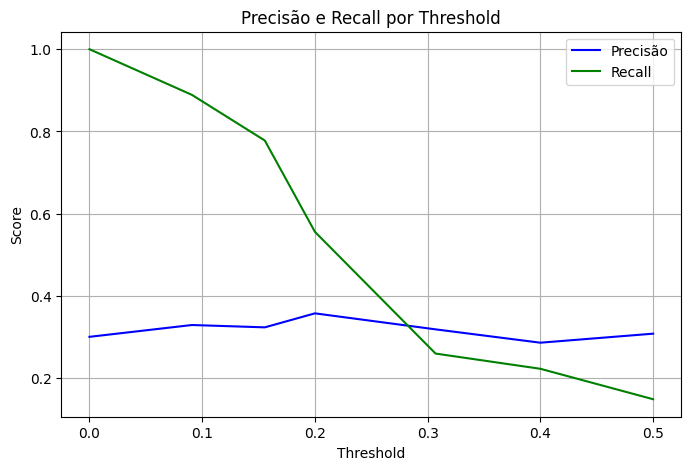

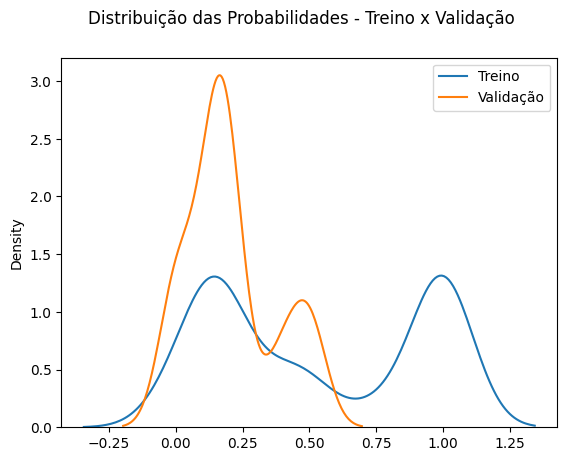

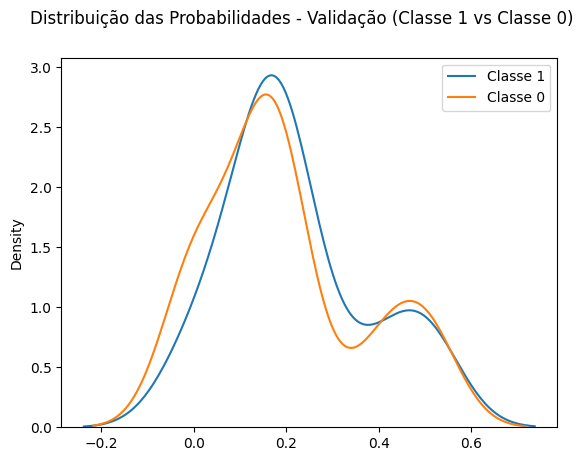

In [ ]:
precisao_minima = 0.6
recall_minimo = None
resultado = tr.avaliar_e_logar_modelo(modelo_reduzido, papel, X_train_reduzido, y_train, X_validacao_reduzido, y_validacao, dias_janela_x=DIAS_JANELA_X, valorizacao=valorizacao, dias_futuro_valorizacao=DIAS_FUTURO, dias_validacao=DIAS_VALIDACAO, recall_minimo=recall_minimo, precisao_minima=precisao_minima)
threshold_calibrado = resultado['threshold_calibrado']
probas = resultado['probas_validacao']
y_true = resultado['y_validacao']
y_pred = resultado['y_pred_validacao']

<Axes: >

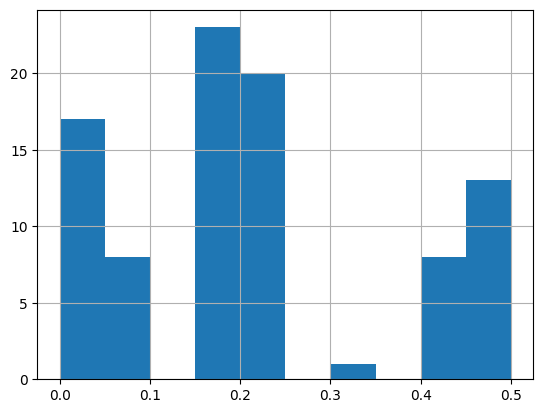

In [ ]:
pd.Series(probas).hist()

In [ ]:
pd.Series(probas).describe()

count    90.000000
mean      0.203468
std       0.161489
min       0.000000
25%       0.090909
50%       0.155556
75%       0.200000
max       0.500000
dtype: float64